In [2]:
# imports
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from plyfile import PlyData
from scipy.ndimage import minimum_filter
from scipy.spatial import cKDTree
from scipy.signal import savgol_filter
import os

In [17]:
# edit root paths
ROOT_PATH = project_root = Path.cwd().parent
KITTI_360_ROOT = Path(ROOT_PATH / "KITTI-360")

SEQ = "2013_05_28_drive_0000_sync"
CAM_ID = 0 # 0 = left pov, 1 right pov
SPLIT = "train"
FRAME = 385
ROAD_ID = 7
SIDEWALK_ID = 8

Read Calibration Data

In [18]:
def load_perspective_calibration(path, cam_id=0):
    dict = {}
    # load as dict
    with open(path / "calibration/perspective.txt") as file:
        for line in file:
            k, v = line.split(":", 1)
            dict[k.strip()] = np.array(v.split())

    proj_matrix = dict[f"P_rect_0{cam_id}"].reshape(3,4)
    width = dict[f"S_rect_0{cam_id}"][0]
    height = dict[f"S_rect_0{cam_id}"][1]

    return proj_matrix, int(float(width)), int(float(height))

def load_cam0_to_world(path, seq):
    file_path = path / "data_poses" / seq / "cam0_to_world.txt"
    data = np.loadtxt(file_path) 
    dict = {
        int(r[0]) : r[1:].reshape(4,4) for r in data
    }
    return dict

proj_matrix, W, H = load_perspective_calibration(KITTI_360_ROOT, CAM_ID)
poses = load_cam0_to_world(KITTI_360_ROOT, SEQ)
print(f"image size: {W, H}")
print(proj_matrix)


image size: (1408, 376)
[['552.554261' '0.000000' '682.049453' '0.000000']
 ['0.000000' '552.554261' '238.769549' '0.000000']
 ['0.000000' '0.000000' '1.000000' '0.000000']]


chunk 3D pointcloud data

In [19]:
def list_static_chunks(path, split, seq):
    file_path = path / "data_3d_semantics" / split / seq / "static" 
    files = sorted(file_path.glob("*.ply"))
    chunks = []
    for file in files:
        start, end = file.stem.split("_")
        chunks.append((int(start), int(end), file))
    return chunks

def chunks_for_frame(chunks, frame):
    return [c for c in chunks if c[0] <= frame <= c[1]]

def load_ply(path):
    v = PlyData.read(str(path))["vertex"]
    names = v.data.dtype.names
    out = {"xyz": np.stack([v["x"], v["y"], v["z"]], 1).astype(np.float64)}
    if "red" in names:
        out["rgb"] = np.stack([v["red"], v["green"], v["blue"]], 1)
    for k in ("semantic", "instance", "confidence", "visible"):
        if k in names:
            out[k] = np.asarray(v[k])
    print(f"{path.name}: {len(out['xyz']):,} points, fields: {names}")
    return out

chunks = list_static_chunks(KITTI_360_ROOT, SPLIT, SEQ)
print(chunks[:5])
print(len(chunks), "static chunks")
hit = chunks_for_frame(chunks, FRAME)
print("chunks covering frame", FRAME, ":", [c[2].name for c in hit])

def load_cloud_for_frame(chunks, frame):
    parts = [load_ply(c[2]) for c in chunks_for_frame(chunks, frame)]
    keys = set.intersection(*[set(p) for p in parts])
    return {k: np.concatenate([p[k] for p in parts]) for k in keys}

cloud = load_cloud_for_frame(chunks, FRAME)

[(2, 385, PosixPath('/Users/adeleyounis/Desktop/polytechnique/1A/CSC_51073/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000002_0000000385.ply')), (372, 610, PosixPath('/Users/adeleyounis/Desktop/polytechnique/1A/CSC_51073/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000372_0000000610.ply')), (599, 846, PosixPath('/Users/adeleyounis/Desktop/polytechnique/1A/CSC_51073/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000599_0000000846.ply')), (834, 1286, PosixPath('/Users/adeleyounis/Desktop/polytechnique/1A/CSC_51073/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000000834_0000001286.ply')), (1270, 1549, PosixPath('/Users/adeleyounis/Desktop/polytechnique/1A/CSC_51073/CurbDetect/KITTI-360/data_3d_semantics/train/2013_05_28_drive_0000_sync/static/0000001270_0000001549.ply'))]
44 static chunks
chunks covering frame 385 : ['0000000002_0000000385.ply'

In [15]:
def project(xyz_world, cam_to_world, proj_matrix, W, H, min_depth=0.5):
    world_to_cam = np.linalg.inv(cam_to_world)

    proj_matrix = proj_matrix.astype(float)
    pc = xyz_world @ world_to_cam[:3, :3].T + world_to_cam[:3, 3] # camera coordinate points
    uvw = pc @ proj_matrix[:, :3].T + proj_matrix[:, 3] # pixel coordinates

    z = uvw[:, 2]
    u = uvw[:, 0] / z
    v = uvw[:, 1] / z

    valid_pts = (z > min_depth) & (u >= 0) & (u < W - 1) & (v >= 0) & (v < H - 1)
    idx = np.where(valid_pts)[0]
    return u[idx], v[idx], z[idx], idx

def visible_mask(u, v, z, W, H, k=5, tol=0.7): 
    depth = np.full((H, W), np.inf)
    u_i, v_i = u.astype(int), v.astype(int)
    order = np.argsort(-z) # far to near pts, nearest written last
    depth[v_i[order], u_i[order]] = z[order]
    local_min = minimum_filter(depth, size=k)
    return z <= local_min[v_i, u_i] + tol

cam_2_world = poses[FRAME]
u, v, z, idx = project(cloud["xyz"], cam_2_world, proj_matrix, W, H)
vis = visible_mask(u, v, z, W, H)
u, v, z, idx = u[vis], v[vis], z[vis], idx[vis]
print(f"{len(idx):,} visible points projected")


202,813 visible points projected


Visualize

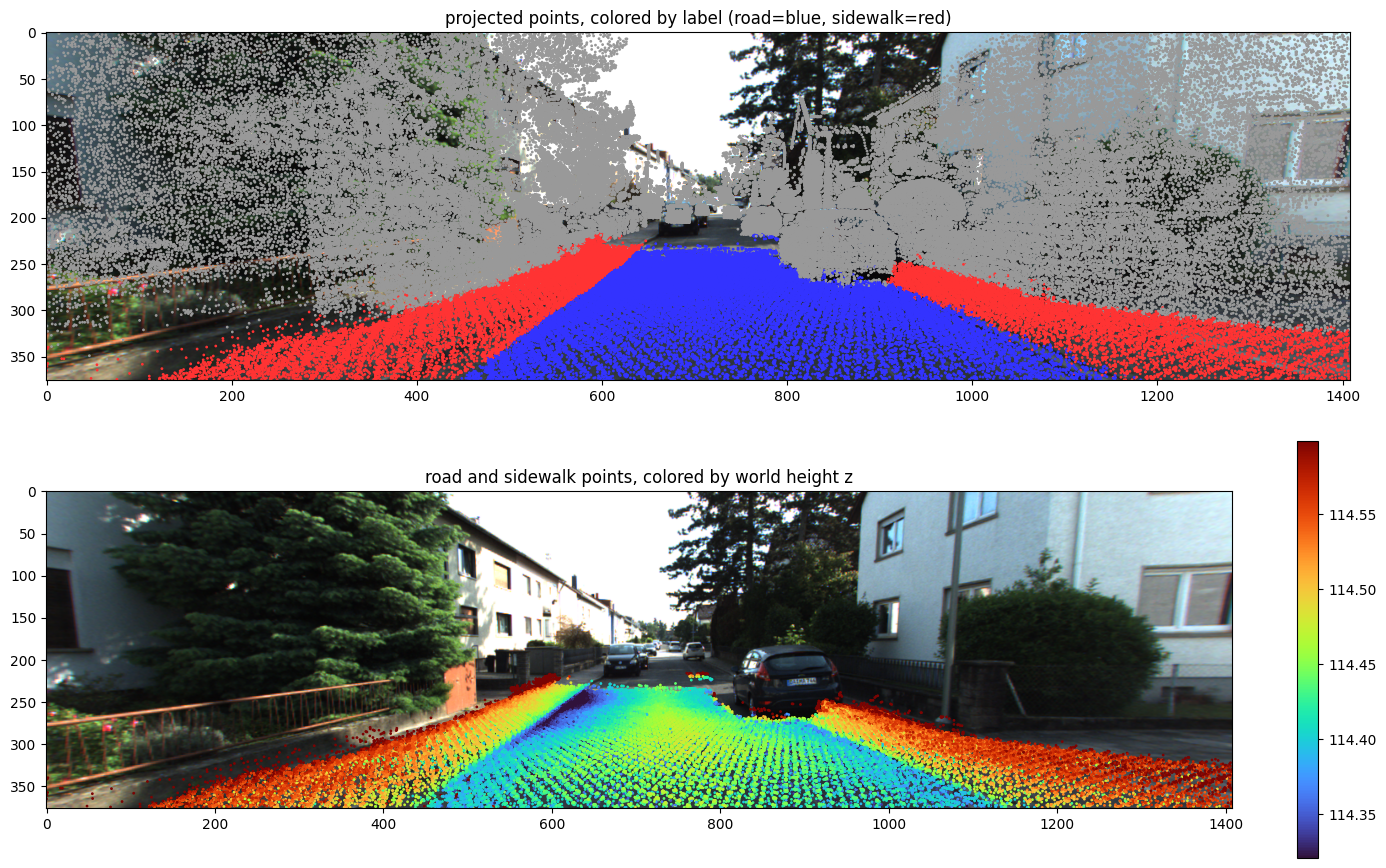

In [20]:
def get_img_path(root, seq, cam_id, frame):
    return root / "data_2d_raw" / seq / f"image_0{cam_id}" / "data_rect" / f"{frame:010d}.png"  

img = np.array(Image.open(get_img_path(KITTI_360_ROOT, SEQ, CAM_ID, FRAME)))

def label_colours(sem):
    colour_mask = np.full((len(sem), 3), 0.6) # everything_grey
    colour_mask[sem == ROAD_ID] = (0.2, 0.2, 1.0) # road = blue
    colour_mask[sem == SIDEWALK_ID] = (1.0, 0.2, 0.2) # sidewalk = red
    return colour_mask

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
for ax in axes:
    ax.imshow(img)

ground = np.isin(cloud["semantic"][idx], [ROAD_ID, SIDEWALK_ID])
axes[0].scatter(u, v, s=1, c=label_colours(cloud["semantic"][idx]))
axes[0].set_title("projected points, colored by label (road=blue, sidewalk=red)")

depth = cloud["xyz"][idx, 2]
lo, hi = np.percentile(depth[ground], [2, 98]) if ground.any() else (depth.min(), depth.max())
sc = axes[1].scatter(u[ground], v[ground], s=1, c=depth[ground], cmap="turbo", vmin=lo, vmax=hi)
axes[1].set_title("road and sidewalk points, colored by world height z")
plt.colorbar(sc, ax=axes[1], fraction=0.04)
plt.tight_layout()
plt.show()

Boundary Exploration

In [21]:
def boundary_candidates(cloud, road_id, sidewalk_id, n=30, radius=0.3, min_spacing=15.0, max_road_pts=300_000, seed=0):
    random_gen = np.random.default_rng(seed)
    xyz = cloud["xyz"][:, :2]
    semantic = cloud["semantic"]
    road = xyz[semantic == road_id] # n x m array
    sidewalk = xyz[semantic == sidewalk_id] # n x m array

    if len(road) == 0 or len(sidewalk) == 0:
        return np.empty((0, 2))
    if len(road) > max_road_pts:
        road = road[random_gen.choice(len(road), max_road_pts, replace=False)] # resample

    distance, _ = cKDTree(sidewalk).query(road, distance_upper_bound=radius) # spatial search mapping closest points of sidewalk to query - within a radius
    edge = road[np.isfinite(distance)]
    random_gen.shuffle(edge) # to not prioritize ordered points

    picked = []
    for p in edge: 
        if all(np.hypot(*(p - q)) > min_spacing for q in picked): # euclidian distance > min spacing threshold between pts
            picked.append(p)
            if len(picked) == n: 
                break
    return np.array(picked)


def analyze_boundary(cloud, center_xy, road_id, sidewalk_id, half=4.0, strip=2.0,
                     edge_radius=0.3, bin_w=0.05, margin=0.15, min_pts=30):
    xyz = cloud["xyz"]
    semantic = cloud["semantic"]
    center_xy = np.asarray(center_xy, float)

    # window around the centered point
    window = (np.abs(xyz[:, 0] - center_xy[0]) < half) & (np.abs(xyz[:, 1] - center_xy[1]) < half)
    window &= np.isin(semantic, [road_id, sidewalk_id])
    idx = np.where(window)[0]

    if len(idx) < min_pts:
        return None
    
    point_coords = xyz[idx, :2]
    z = xyz[idx, 2]

    road = point_coords[semantic[idx] == road_id]
    side = point_coords[semantic[idx] == sidewalk_id]

    if len(road) < 10 or len(side) < 10:
        return None

    # label-edge points: road points that touch sidewalk points
    dist, _ = cKDTree(side).query(road, distance_upper_bound=edge_radius)
    edge = road[np.isfinite(dist)]
    if len(edge) < 10:
        return None

    # local frame: t along the boundary (PCA), n across it, pointing road -> sidewalk
    o = edge.mean(0)
    w, v = np.linalg.eigh(np.cov((edge - o).T))
    t = v[:, np.argmax(w)]
    n = np.array([-t[1], t[0]])
    if (side.mean(0) - road.mean(0)) @ n < 0:
        n = -n

    # restrict to a strip around the center
    along, across = (point_coords - o) @ t, (point_coords - o) @ n
    keep = np.abs(along) < strip / 2

    if keep.sum() < min_pts:
        return None
    
    boundary_pt_pos, height, label = across[keep], z[keep], semantic[idx][keep]
    road_pos = boundary_pt_pos[label == road_id]
    sidewalk_pos = boundary_pt_pos[label == sidewalk_id]

    if len(road_pos) < 5 or len(sidewalk_pos) < 5:
        return None

    # get rid of extremes
    semantic_label = 0.5 * (np.percentile(road_pos, 95) + np.percentile(sidewalk_pos, 5))

    # identify edges
    edges = np.arange(boundary_pt_pos.min(), boundary_pt_pos.max() + bin_w, bin_w)
    b = np.digitize(boundary_pt_pos, edges)

    centers, meds, cnt = [], [], []
    for k in np.unique(b):
        m = b == k
        if m.sum() >= 3:
            centers.append(boundary_pt_pos[m].mean()); meds.append(np.median(height[m])); cnt.append(m.sum())
    centers, meds, cnt = map(np.array, (centers, meds, cnt))

    if len(centers) < 6:
        return None

    # smooth the binned median heights
    meds_smooth = savgol_filter(meds, window_length=5, polyorder=2)

    if len(centers) < 6:
        return None

    # fit the step between the two
    best = np.inf # want this to be a min 
    step = np.nan

    for i in range(2, len(centers) - 2):
        left = slice(0, i) # split at the boundary i
        right = slice(i, None)
        left_avg = np.average(meds_smooth[left], weights=cnt[left])
        right_avg = np.average(meds_smooth[right], weights=cnt[right])
        cost = (cnt[left] * (meds_smooth[left] - left_avg) ** 2).sum() + (cnt[right] * (meds_smooth[right] - right_avg) ** 2).sum() # weighted squared error for both left anf right sides around the boundary
        
        if cost < best:
            best = cost
            step = 0.5 * (centers[i - 1] + centers[i]) # step is the midpoint

    left, right = boundary_pt_pos < step - margin, boundary_pt_pos > step + margin

    if left.sum() >= 5 and right.sum() >= 5:
        step_cm = (np.median(height[right]) - np.median(height[left])) * 100
    else: 
        step_cm = np.nan

    return dict(center=center_xy, o=o, t=t, n=n, s=boundary_pt_pos, z=height, lab=label, bins=(centers, meds_smooth),
                s_label=semantic_label, s_step=step, step_cm=step_cm,
                offset_cm=(step - semantic_label) * 100, window=(point_coords, semantic[idx], z),
                road_id=road_id, sidewalk_id=sidewalk_id)


# 0 step=   7.1 cm  offset=  11.6 cm
# 1 step=   8.5 cm  offset=  83.5 cm
# 2 step=   7.4 cm  offset=   6.6 cm
# 3 step=   5.1 cm  offset=  27.7 cm
# 4 step=   8.0 cm  offset=   5.3 cm
# 5 step=  -4.1 cm  offset=-146.7 cm
# 6 step=   9.6 cm  offset=  64.6 cm
# 7 step=   5.3 cm  offset=  25.2 cm
# 8 step=  11.1 cm  offset=  -3.4 cm
# 9 step=   7.3 cm  offset=  53.9 cm
#10 step=   7.1 cm  offset=  26.9 cm
#11 step=   7.1 cm  offset=  68.0 cm


[(0,
  1035.5079345703125,
  3860.8076171875,
  7.13958740234375,
  11.589575237663556),
 (1,
  1165.0699462890625,
  4002.800048828125,
  8.47015380859375,
  83.5239263540136),
 (2,
  1150.945068359375,
  3987.22119140625,
  7.399749755859375,
  6.602852342580658),
 (3,
  1083.9200439453125,
  3922.14990234375,
  5.14984130859375,
  27.656732412912703),
 (4, 1045.56005859375, 3872.080078125, 8.00018310546875, 5.299604128007234),
 (5,
  1129.8580322265625,
  3972.593994140625,
  -4.10003662109375,
  -146.7209465906219),
 (6, 1098.93994140625, 3930.31005859375, 9.600067138671875, 64.56051488669067),
 (7,
  1118.3299560546875,
  3959.77001953125,
  5.300140380859375,
  25.163927568775428),
 (8,
  1077.050048828125,
  3906.14990234375,
  11.100006103515625,
  -3.371773109527392),
 (9, 1111.4599609375, 3943.79931640625, 7.2998046875, 53.887441125861024),
 (10,
  1015.8995971679688,
  3847.744873046875,
  7.120513916015625,
  26.851387600910915),
 (11,
  1060.5069580078125,
  3888.169677734

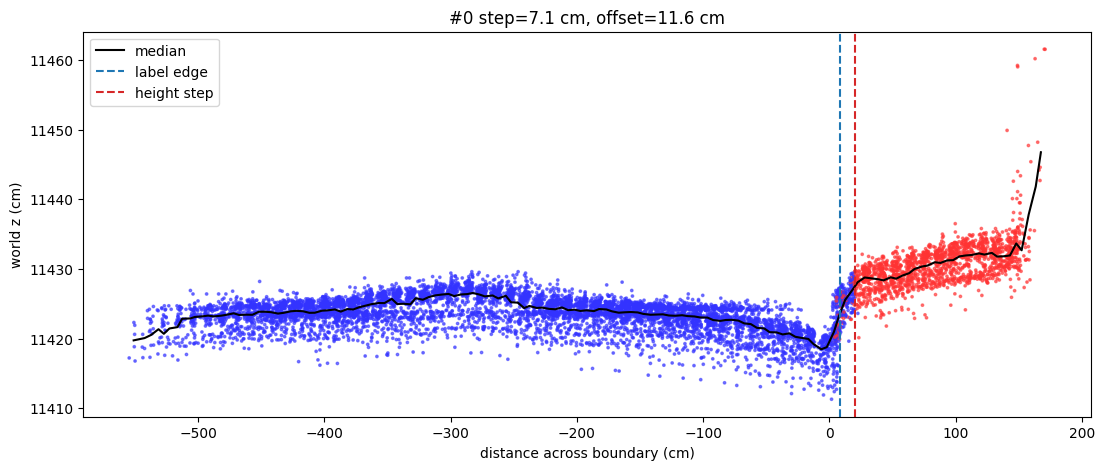

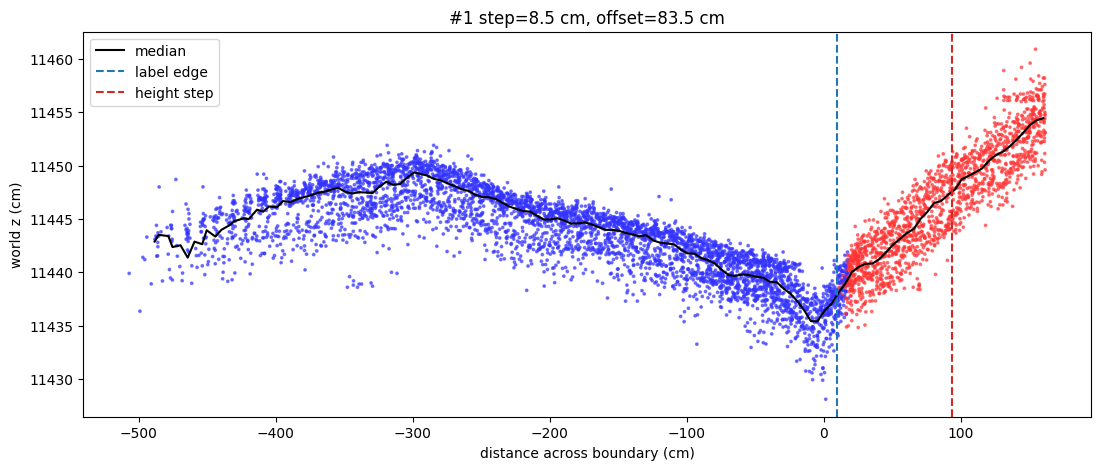

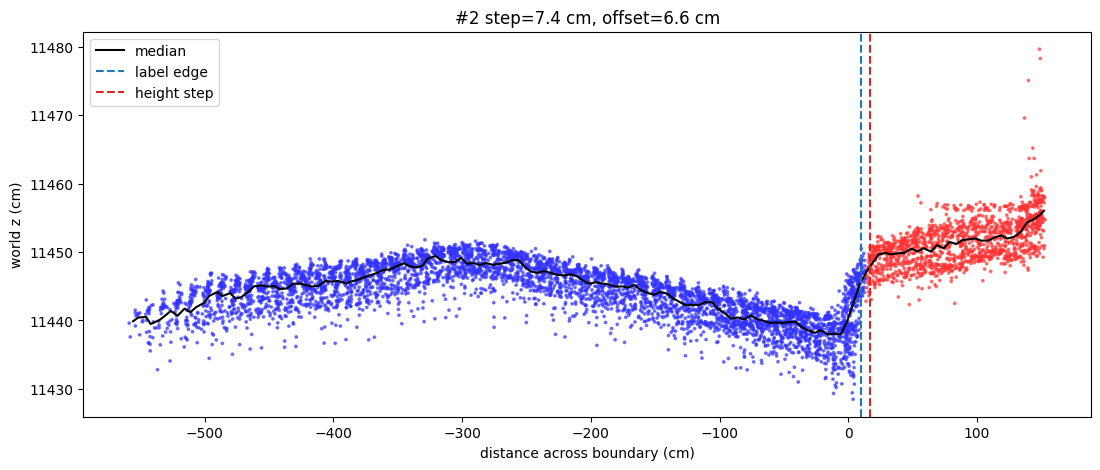

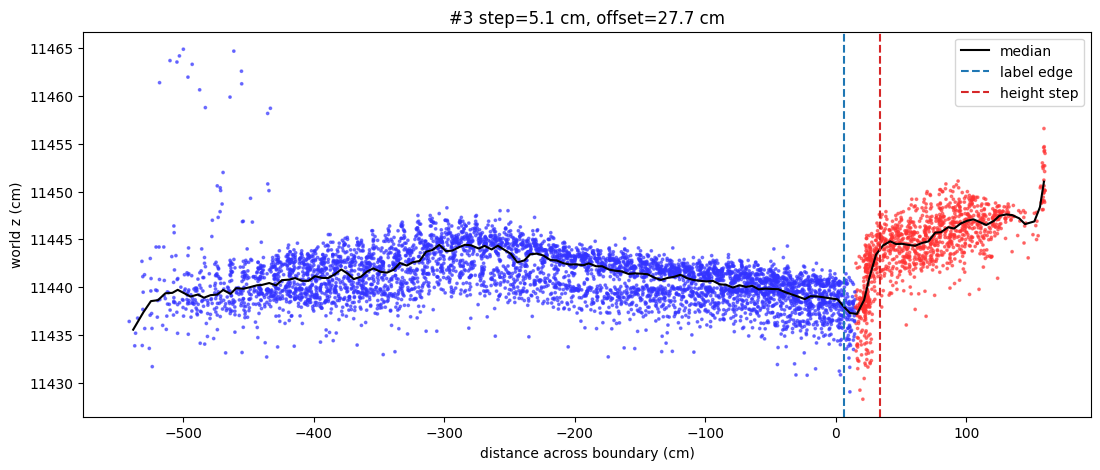

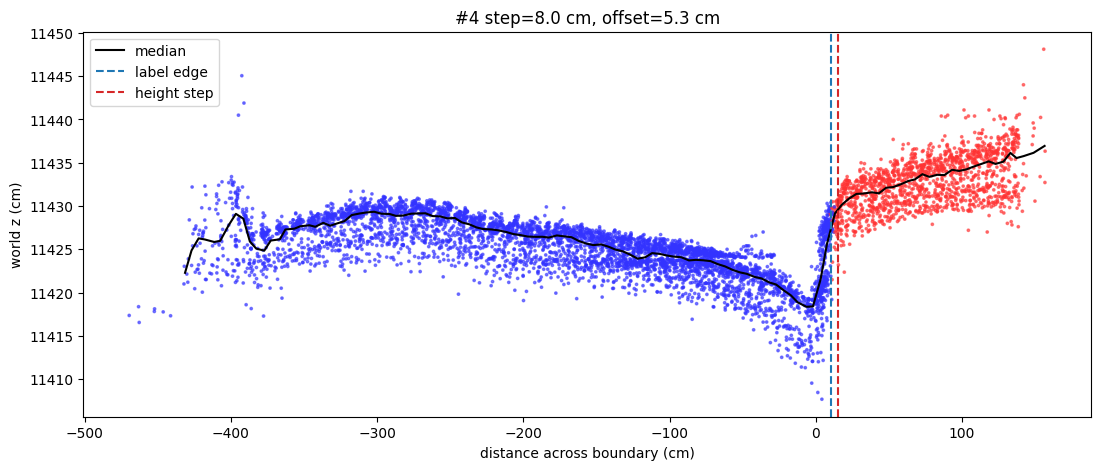

In [24]:
def plot_analysis(res, title=""):
    if res is None:
        print("no result to plot"); return
    
    blue = [0.2, 0.2, 1.0] # road = blue
    red = [1.0, 0.2, 0.2] # sidewalk = red

    rid = res["road_id"]
    fig, ax = plt.subplots(1, 1, figsize=(13, 5))

    c = np.where(res["lab"][:, None] == rid, [blue], [red])

    ax.scatter(res["s"] * 100, res["z"] * 100, s=3, c=c, alpha=0.6)
    ax.plot(res["bins"][0] * 100, res["bins"][1] * 100, "k-", lw=1.5, label="median")
    ax.axvline(res["s_label"] * 100, color="tab:blue", ls="--", label="label edge")
    ax.axvline(res["s_step"] * 100, color="tab:red", ls="--", label="height step")
    ax.set_xlabel("distance across boundary (cm)")
    ax.set_ylabel("world z (cm)")
    ax.set_title(f"{title} step={res['step_cm']:.1f} cm, offset={res['offset_cm']:.1f} cm")
    ax.legend()


def run_boundary_test(cloud, road_id, sidewalk_id, n=20, plot_first=5, **kw):
    cands = boundary_candidates(cloud, road_id, sidewalk_id, n=n)
    rows = []                                    # collect results here
    for i, c in enumerate(cands):
        r = analyze_boundary(cloud, c, road_id, sidewalk_id, **kw)
        if r is None:
            continue
        rows.append((i, c[0], c[1], r["step_cm"], r["offset_cm"]))
        print(f"#{i:2d} step={r['step_cm']:6.1f} cm  offset={r['offset_cm']:6.1f} cm")
        if i < plot_first:
            plot_analysis(r, title=f"#{i}")
    return rows                                  # this line is what's missing
run_boundary_test(cloud, ROAD_ID, SIDEWALK_ID)

things to look into: 
- looking at two platueas or flat regions, make it look at sloped curbs as well
    - what about when its all flat?
- fix so that it knows whether the curb is on the right side or leftside of this road view - the step asymptote should always follow this formatting
- smooth even more, model as piecewise for sharper transitions??
- play around with params to see what gives the best results? maybe do some type of DOE

0000001537_0000001755.ply: 2,476,010 points, fields: ('x', 'y', 'z', 'red', 'green', 'blue', 'semantic', 'instance', 'visible', 'confidence')
# 0 step=   7.1 cm  offset=  11.6 cm
# 1 step=   8.5 cm  offset=  83.5 cm
# 2 step=   7.4 cm  offset=   6.6 cm
# 3 step=   5.1 cm  offset=  27.7 cm
# 4 step=   8.0 cm  offset=   5.3 cm
0000001740_0000001991.ply: 3,007,107 points, fields: ('x', 'y', 'z', 'red', 'green', 'blue', 'semantic', 'instance', 'visible', 'confidence')
# 0 step=   9.1 cm  offset=   6.6 cm
# 1 step=   6.3 cm  offset=  31.4 cm
# 2 step=   6.9 cm  offset=  15.6 cm
# 3 step=   5.4 cm  offset=   2.2 cm
# 4 step=   6.3 cm  offset=  93.8 cm
0000001980_0000002295.ply: 3,674,701 points, fields: ('x', 'y', 'z', 'red', 'green', 'blue', 'semantic', 'instance', 'visible', 'confidence')
# 0 step=  11.4 cm  offset=  -1.3 cm
# 1 step=   4.4 cm  offset=  73.5 cm
# 2 step=   9.0 cm  offset= -16.8 cm
# 3 step=   3.7 cm  offset=   8.8 cm
# 4 step=  10.2 cm  offset=  32.1 cm
0000002282_00000025

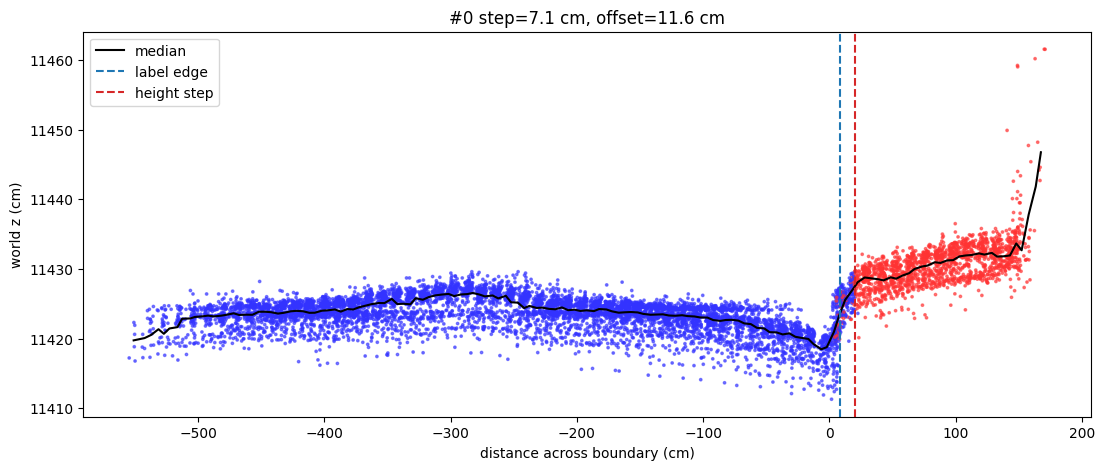

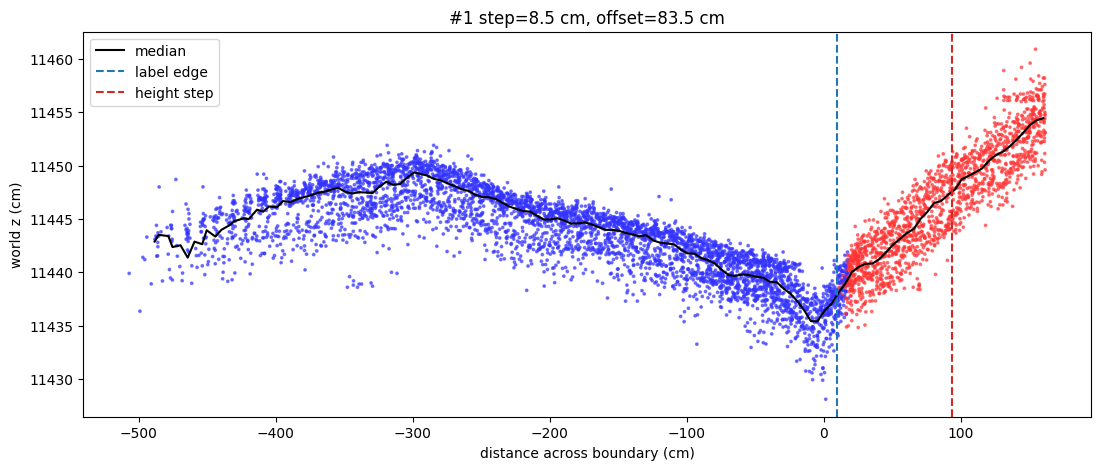

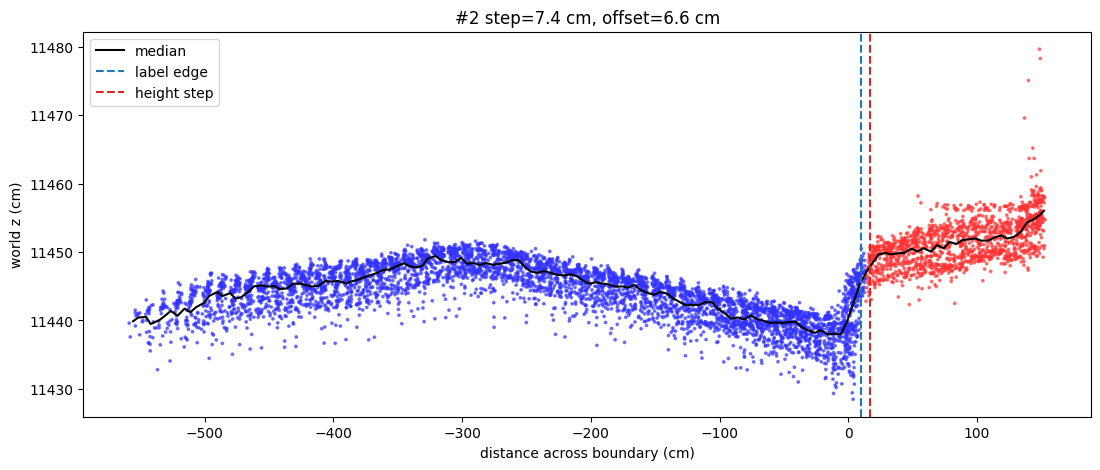

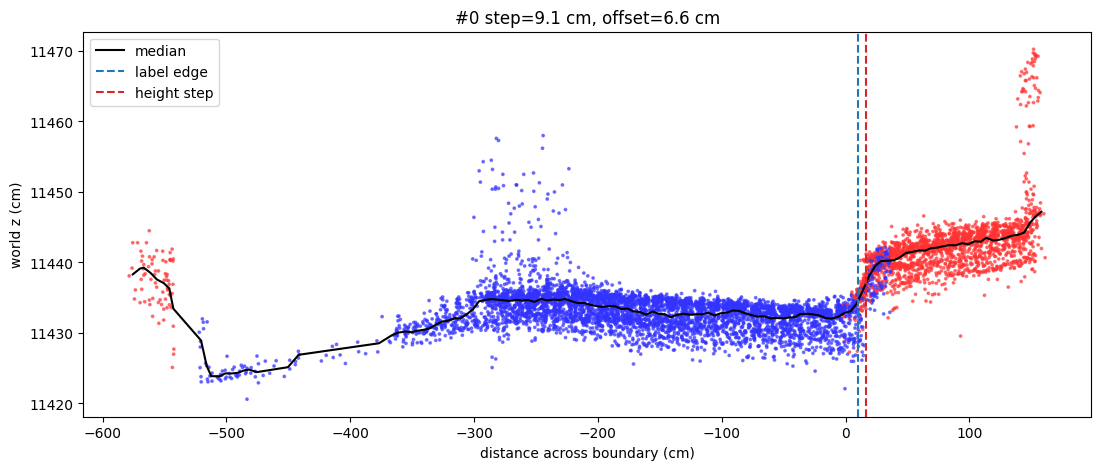

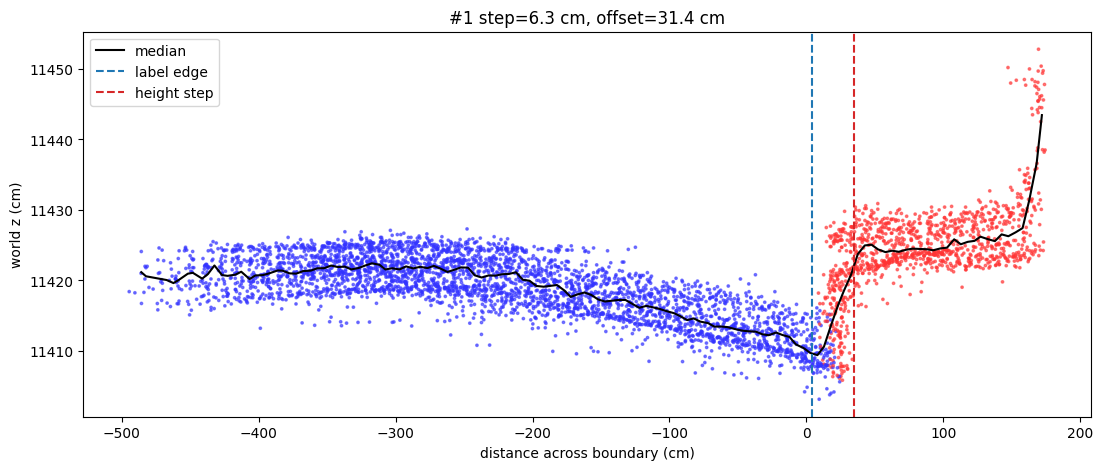

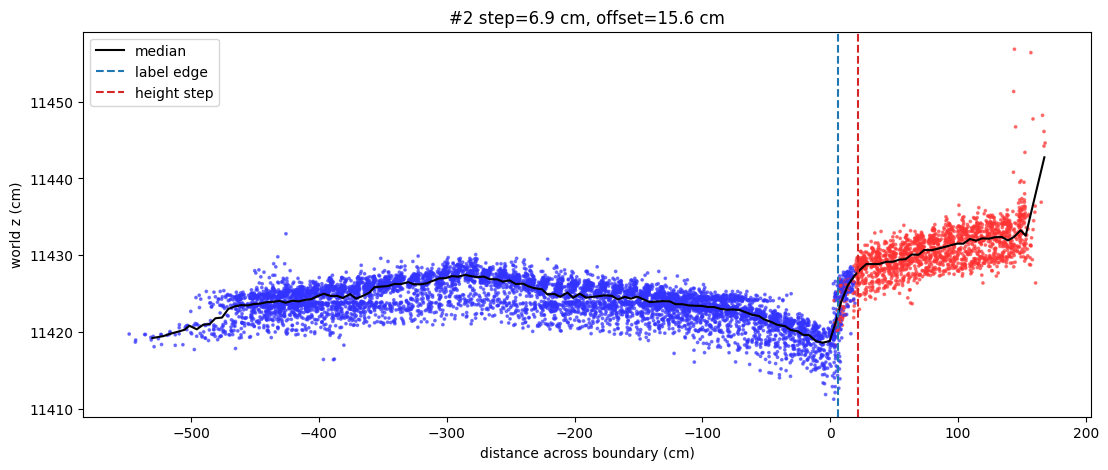

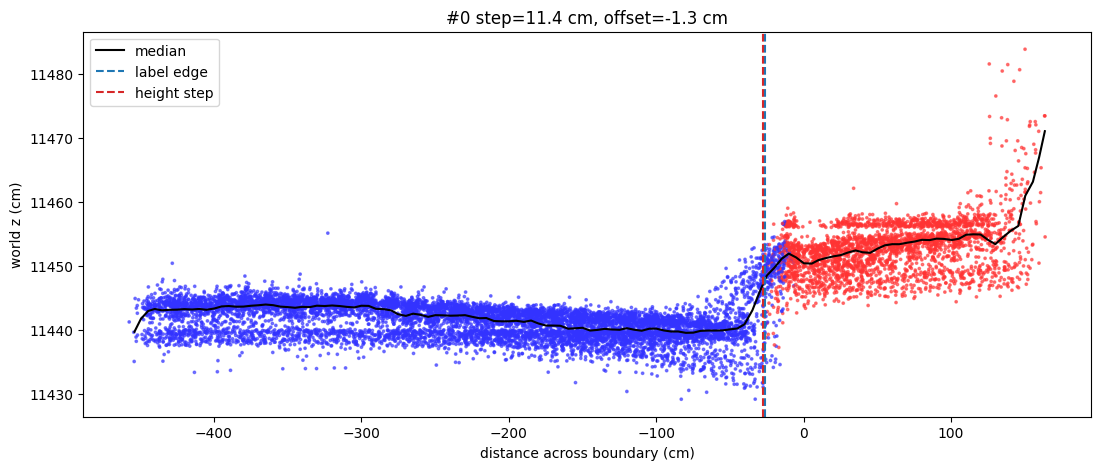

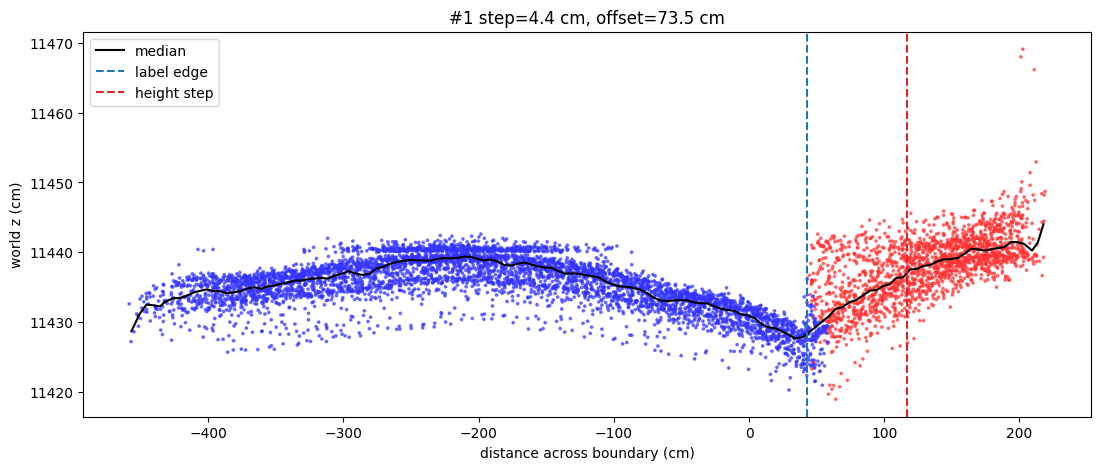

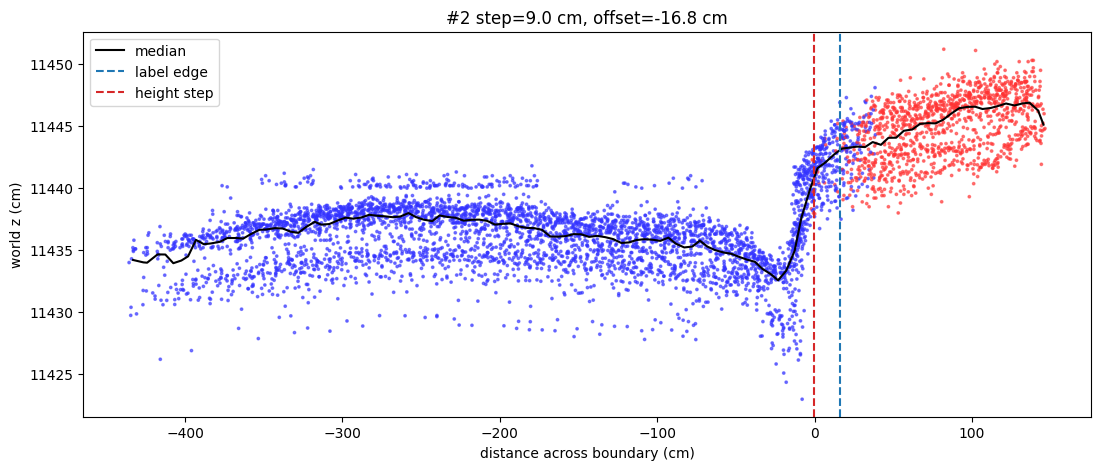

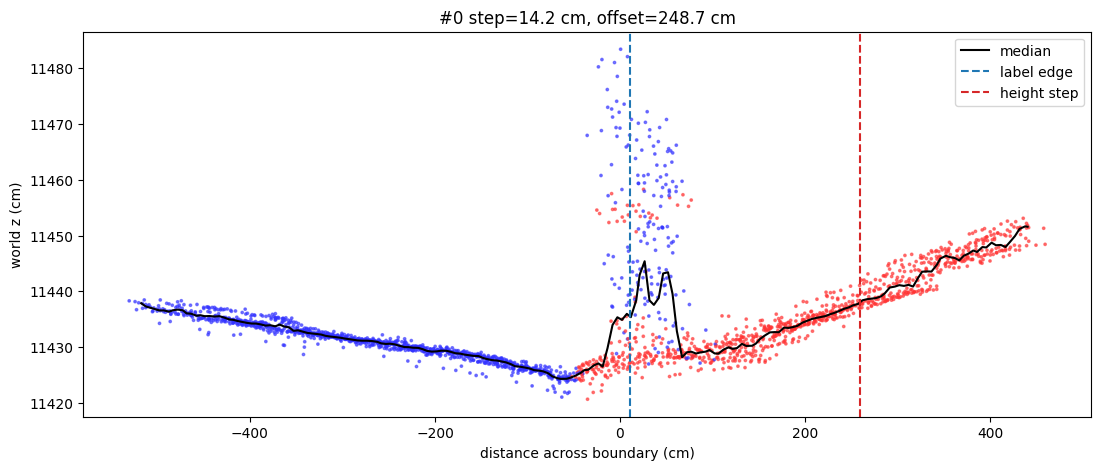

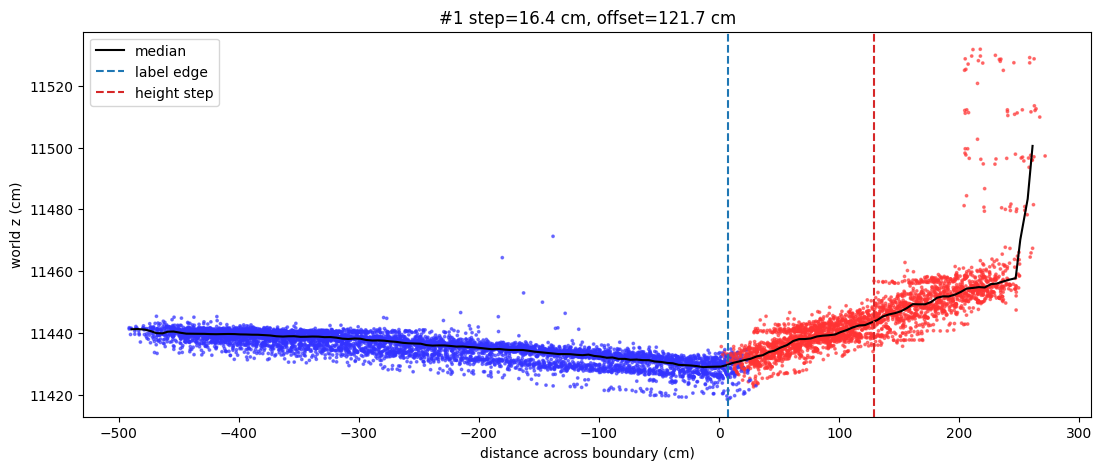

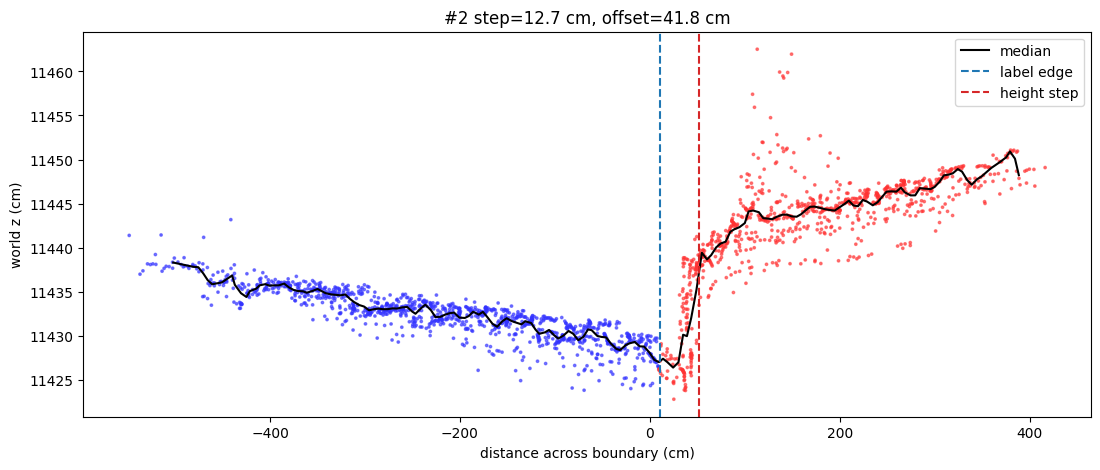

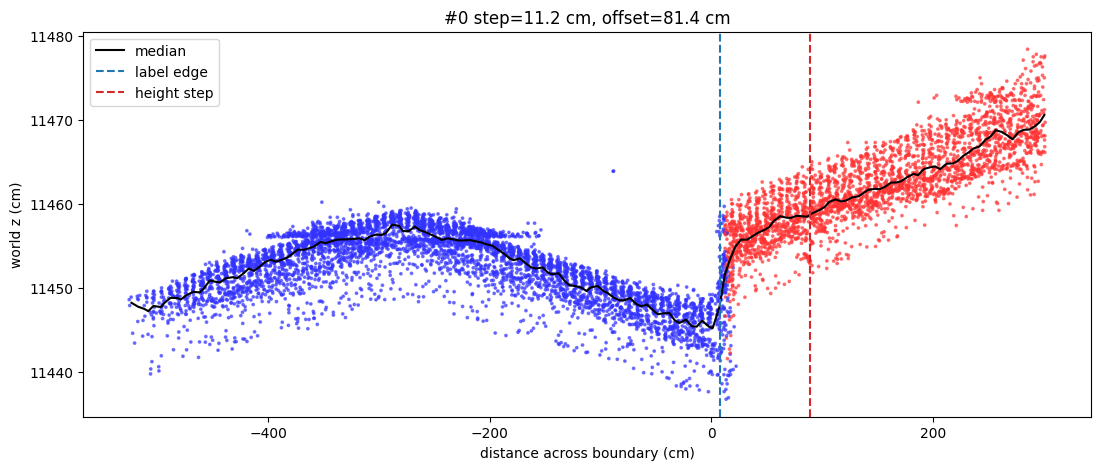

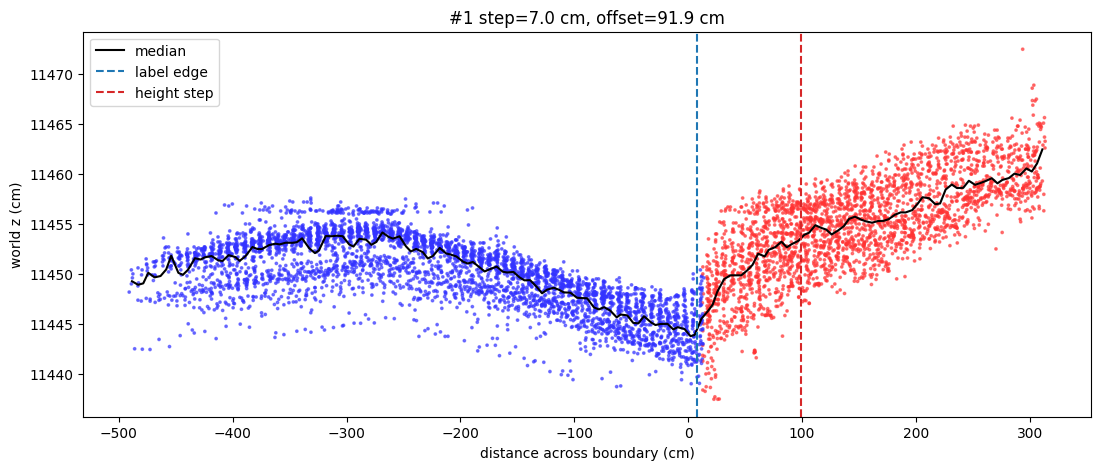

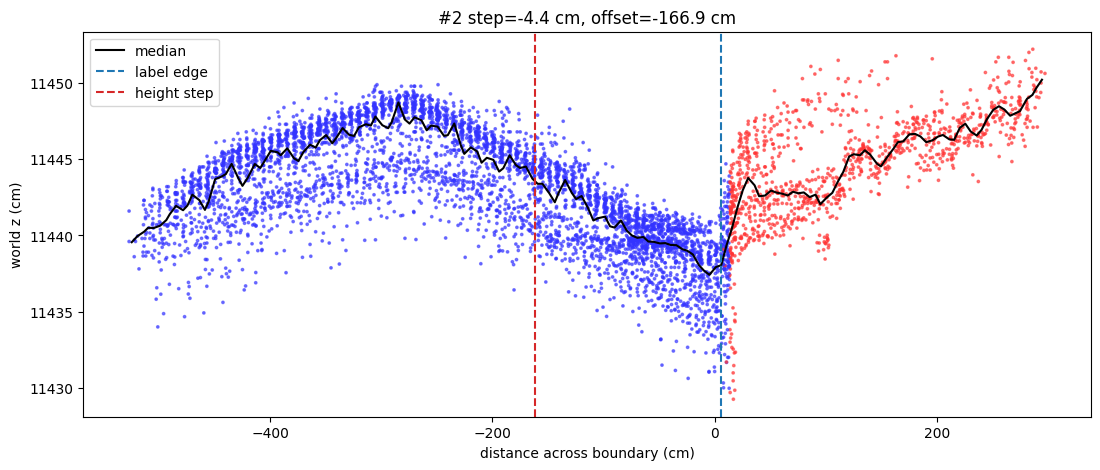

In [25]:
all_rows = []
for start, end, path in chunks[5:10]:
    cloud = load_ply(path)
    rows = run_boundary_test(cloud, ROAD_ID, SIDEWALK_ID, n=5, plot_first=3)
    all_rows += [(path.name, *r[1:]) for r in rows]   
    del cloud                                         

In [ ]:
# 